In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

In [ ]:
transform = transforms.ToTensor()

train_data = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=128, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=128, shuffle=False
)

print("MNIST dataset loaded")

100%|██████████| 9.91M/9.91M [00:00<00:00, 65.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.71MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]

MNIST dataset loaded


In [ ]:
class MLP(nn.Module):
    def __init__(self, activation):
        super().__init__()

        if activation == "Sigmoid":
            act = nn.Sigmoid()
        elif activation == "Tanh":
            act = nn.Tanh()
        else:
            act = nn.ReLU()

        self.fc1 = nn.Linear(784, 128)
        self.act1 = act

        self.fc2 = nn.Linear(128, 128)
        self.act2 = act

        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))

        x = self.fc3(x)
        return x

In [ ]:
def train_model(activation, epochs=3):

    model = MLP(activation)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    train_accuracies = []
    test_accuracies = []
    gradient_history = []

    start_time = time.time()

    for epoch in range(epochs):

        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()

            # Record gradient flow from hidden layers
            grad1 = model.fc1.weight.grad.norm().item()
            grad2 = model.fc2.weight.grad.norm().item()

            optimizer.step()

            gradient_history.append([grad1, grad2])

            total_loss += loss.item()
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_losses.append(total_loss / len(train_loader))
        train_accuracies.append(100 * correct / total)

        # Test accuracy
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                outputs = model(images)
                predicted = outputs.argmax(dim=1)

                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        test_acc = 100 * correct / total
        test_accuracies.append(test_acc)

        print(
            activation,
            "Epoch:", epoch + 1,
            "Loss:", round(train_losses[-1], 4),
            "Train Accuracy:", round(train_accuracies[-1], 2),
            "Test Accuracy:", round(test_acc, 2)
        )

    training_time = time.time() - start_time

    return (
        model,
        train_losses,
        train_accuracies,
        test_accuracies,
        gradient_history,
        training_time
    )

In [ ]:
results = {}

for activation in ["Sigmoid", "Tanh", "ReLU"]:

    results[activation] = train_model(
        activation,
        epochs=3
    )

Sigmoid Epoch: 1 Loss: 0.8252 Train Accuracy: 77.83 Test Accuracy: 91.41
Sigmoid Epoch: 2 Loss: 0.2589 Train Accuracy: 92.57 Test Accuracy: 93.65
Sigmoid Epoch: 3 Loss: 0.1898 Train Accuracy: 94.44 Test Accuracy: 94.74
Tanh Epoch: 1 Loss: 0.3719 Train Accuracy: 89.83 Test Accuracy: 94.49
Tanh Epoch: 2 Loss: 0.1558 Train Accuracy: 95.31 Test Accuracy: 96.0
Tanh Epoch: 3 Loss: 0.1089 Train Accuracy: 96.67 Test Accuracy: 96.71
ReLU Epoch: 1 Loss: 0.3879 Train Accuracy: 89.09 Test Accuracy: 94.46
ReLU Epoch: 2 Loss: 0.1548 Train Accuracy: 95.45 Test Accuracy: 96.2
ReLU Epoch: 3 Loss: 0.1065 Train Accuracy: 96.89 Test Accuracy: 97.03


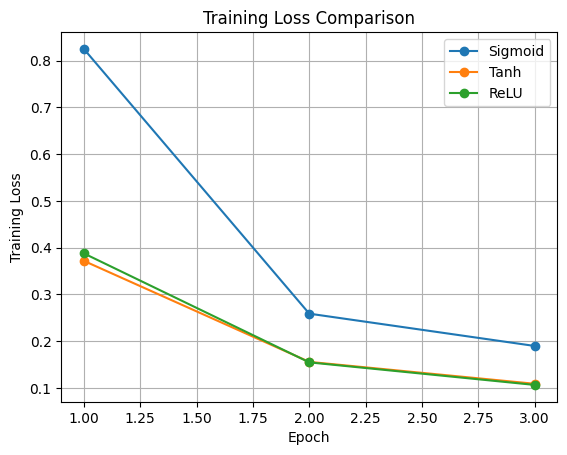

In [ ]:
for activation in results:
    train_loss = results[activation][1]

    plt.plot(
        range(1, len(train_loss) + 1),
        train_loss,
        marker="o",
        label=activation
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid()
plt.show()

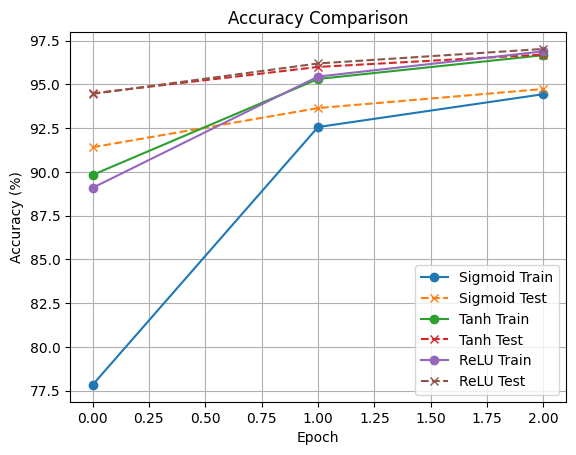

In [ ]:
for activation in results:
    train_acc = results[activation][2]
    test_acc = results[activation][3]

    plt.plot(train_acc, marker="o",
             label=activation + " Train")

    plt.plot(test_acc, marker="x", linestyle="--",
             label=activation + " Test")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")
plt.legend()
plt.grid()
plt.show()

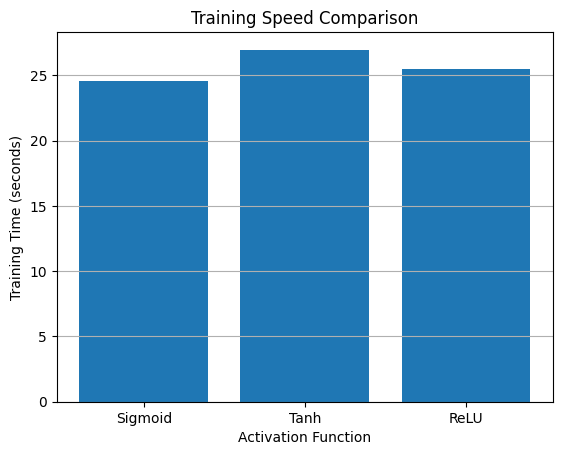

Sigmoid Training Time: 24.57 seconds
Tanh Training Time: 26.97 seconds
ReLU Training Time: 25.51 seconds


In [ ]:
activations = list(results.keys())
times = [results[a][5] for a in activations]

plt.bar(activations, times)

plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")
plt.title("Training Speed Comparison")
plt.grid(axis="y")
plt.show()

for a in activations:
    print(a, "Training Time:",
          round(results[a][5], 2), "seconds")

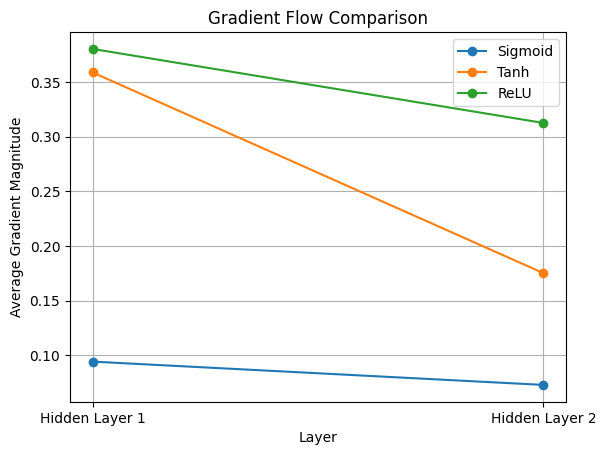

In [ ]:
for activation in results:

    gradients = results[activation][4]

    gradients = torch.tensor(gradients)

    # Average gradient for each layer
    layer1_grad = gradients[:, 0].mean().item()
    layer2_grad = gradients[:, 1].mean().item()

    plt.plot(
        ["Hidden Layer 1", "Hidden Layer 2"],
        [layer1_grad, layer2_grad],
        marker="o",
        label=activation
    )

plt.xlabel("Layer")
plt.ylabel("Average Gradient Magnitude")
plt.title("Gradient Flow Comparison")
plt.legend()
plt.grid()
plt.show()

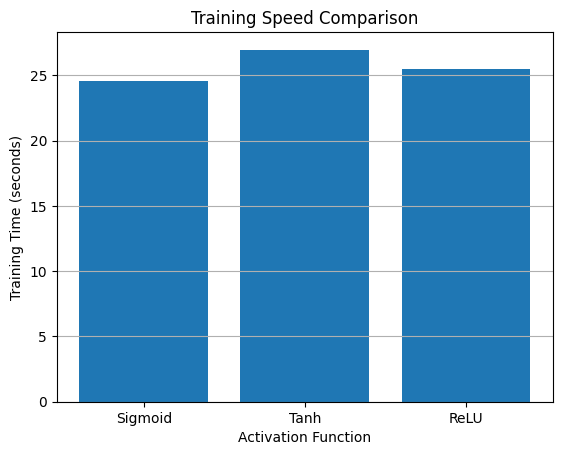

Sigmoid Training Time: 24.57 seconds
Tanh Training Time: 26.97 seconds
ReLU Training Time: 25.51 seconds


In [ ]:
activations = list(results.keys())
times = [results[a][5] for a in activations]

plt.bar(activations, times)

plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")
plt.title("Training Speed Comparison")
plt.grid(axis="y")
plt.show()

for a in activations:
    print(a, "Training Time:",
          round(results[a][5], 2), "seconds")

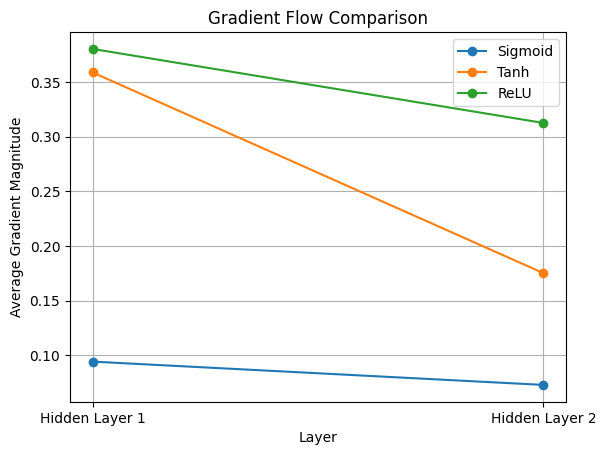

In [ ]:
for activation in results:

    gradients = results[activation][4]

    gradients = torch.tensor(gradients)

    # Average gradient for each layer
    layer1_grad = gradients[:, 0].mean().item()
    layer2_grad = gradients[:, 1].mean().item()

    plt.plot(
        ["Hidden Layer 1", "Hidden Layer 2"],
        [layer1_grad, layer2_grad],
        marker="o",
        label=activation
    )

plt.xlabel("Layer")
plt.ylabel("Average Gradient Magnitude")
plt.title("Gradient Flow Comparison")
plt.legend()
plt.grid()
plt.show()

In [ ]:
for activation in results:
    final_accuracy = results[activation][3][-1]

    print(
        activation,
        "Final Test Accuracy:",
        round(final_accuracy, 2), "%"
    )

Sigmoid Final Test Accuracy: 94.74 %
Tanh Final Test Accuracy: 96.71 %
ReLU Final Test Accuracy: 97.03 %
